In [2391]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


class Neural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        
        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.sigmoid(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat
    
    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))
    
    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)
    
    def relu(self, z):
        return np.maximum(0, z)
    
    def reluPrime(self,z):
        return 1 * (z > 0)

    def costFunctionPrimeRelu(self, X, y):
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.reluPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def forwardRelu(self,X):
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.relu(self.z3)
        return yHat

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J

    def costFunctionRelu(self, X,y):
        self.yHat=self.forwardRelu(X)
        J=0.5*sum((y-self.yHat)**2)
        return J
    
    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.sigmoidPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2


In [2392]:
X=np.array(([3,5],[5,1],[10,1]),dtype=float)
y=np.array(([75],[80],[93]),dtype=float)

In [2393]:
X


array([[ 3.,  5.],
       [ 5.,  1.],
       [10.,  1.]])

In [2394]:
y

array([[75.],
       [80.],
       [93.]])

In [2395]:
X=X/np.amax(X,axis=0)
y=y/100

In [2396]:
X,y


(array([[0.3, 1. ],
        [0.5, 0.2],
        [1. , 0.2]]),
 array([[0.75],
        [0.8 ],
        [0.93]]))

In [2397]:
NN=Neural_Network()

In [2398]:
yH=NN.forward(X)

In [2399]:
yH

array([[0.76776684],
       [0.74275135],
       [0.7639806 ]])

In [2400]:
y

array([[0.75],
       [0.8 ],
       [0.93]])

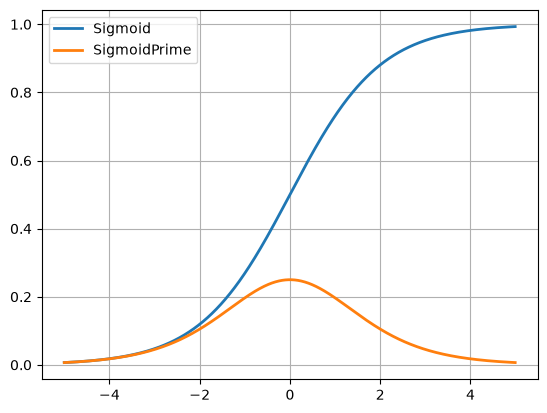

In [2401]:
testValues=np.arange(-5,5,0.01)
plt.plot(testValues,NN.sigmoid(testValues),linewidth=2)
plt.plot(testValues, NN.sigmoidPrime(testValues),linewidth=2)
plt.grid(1)
plt.legend(['Sigmoid','SigmoidPrime'])


In [2402]:
NN=Neural_Network()

In [2403]:
cost1=NN.costFunction(X,y)

In [2404]:
cost1

array([0.0268585])

In [2405]:
dJdW1,dJdW2=NN.costFunctionPrime(X,y)

In [2406]:
dJdW1

array([[-0.01065145, -0.00414853, -0.0040466 ],
       [-0.00321352, -0.00121906, -0.00121877]])

In [2407]:
dJdW2

array([[-0.03958369],
       [-0.04042378],
       [-0.04333996]])

In [2408]:
scalar= 3
NN.W1 = NN.W1+scalar*dJdW1
NN.W2 = NN.W2+scalar*dJdW2
cost2 = NN.costFunction(X,y)
print (cost1,cost2)

[0.0268585] [0.04714437]


In [2409]:
scalar= 3 #this is our alpha
NN.W1 = NN.W1-scalar*dJdW1
NN.W2 = NN.W2-scalar*dJdW2
cost3 = NN.costFunction(X,y)
print (cost2,cost3)

[0.04714437] [0.0268585]


In [2410]:
# NN.W1 = NN.W1 + scalar*(NN.yHat-NN.a3)*NN.sigmoidPrime(NN.z3)*array([NN.X[0,0], NN.X[0,1], NN.X[0,2]],[NN.X[1,0], NN.X[1,1], NN.X[1,2]])
# NN.W1

[[0.37048268 0.31196617 0.59982973]
 [0.42687505 0.84479427 0.67379325]] [[0.83374123]
 [0.32758485]
 [0.34000867]]


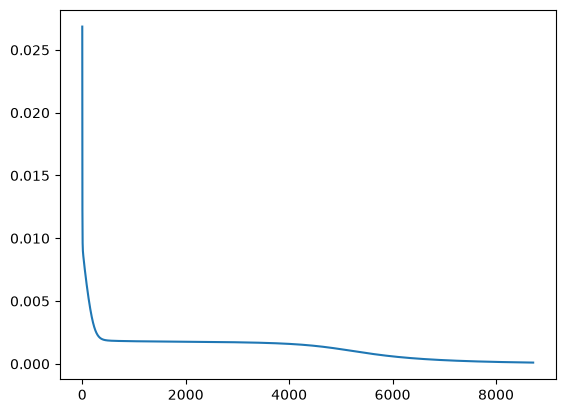

In [2411]:
def minimize(alpha, accuracyPoop):
    W1_init = NN.W1
    W2_init = NN.W2
    print(W1_init,W2_init)
    cost = NN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = NN.costFunctionPrime(X, y)

        NN.W1 = NN.W1-alpha*dJdW1
        NN.W2 = NN.W2-alpha*dJdW2

        cost = NN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arr = (minimize(2, .0001))

# print(cost_arr)
plt.plot(cost_arr)

In [2412]:
sigmoid_loss = NN.forward(X)-y

In [2413]:

class ReluNeural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)


[[0.67878596 0.47778508 0.66937443]
 [0.14516179 0.97634077 0.66517801]] [[0.5421008 ]
 [0.42874591]
 [0.30899451]]


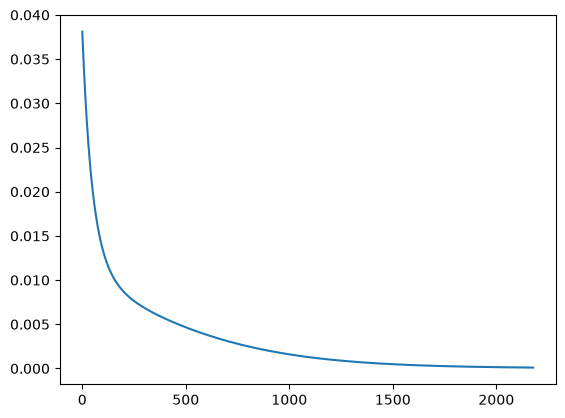

In [2414]:
ReluNN = ReluNeural_Network()

def minimizeRelu(alpha, accuracyPoop, ReluNN):
    W1_init = ReluNN.W1
    W2_init = ReluNN.W2
    print(W1_init,W2_init)
    cost = ReluNN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = ReluNN.costFunctionPrime(X, y)

        ReluNN.W1 = ReluNN.W1-alpha*dJdW1
        ReluNN.W2 = ReluNN.W2-alpha*dJdW2

        cost = ReluNN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arrRelu = (minimizeRelu(.05, .0001, ReluNN))

# print(cost_arr)
plt.plot(cost_arrRelu)

In [2415]:
relu_loss = ReluNN.forward(X)-y

In [2416]:
class ReluNeural_Network_Extra(object):
    def __init__(self, size):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        self.hiddenLayer_2_Size = size

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.hiddenLayer_2_Size)
        self.W3=np.random.rand(self.hiddenLayer_2_Size,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        self.a3 = self.relu(self.z3)
        self.z4 = np.dot(self.a3, self.W3)
        yHat = self.sigmoid(self.z4)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta4 = np.multiply(-(y-self.yHat), self.sigmoidPrime(self.z4))
        dJdW3=np.dot(self.a3.T, delta4)
        delta3 = np.dot(delta4, self.W3.T)* self.reluPrime(self.z3)
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2, dJdW3

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)



[[0.97391092 0.54101864 0.19051036]
 [0.55675169 0.60851507 0.83737335]] [[0.58150008 0.0134817  0.32931222]
 [0.51451244 0.31254647 0.25409962]
 [0.57159468 0.16639442 0.56510332]]


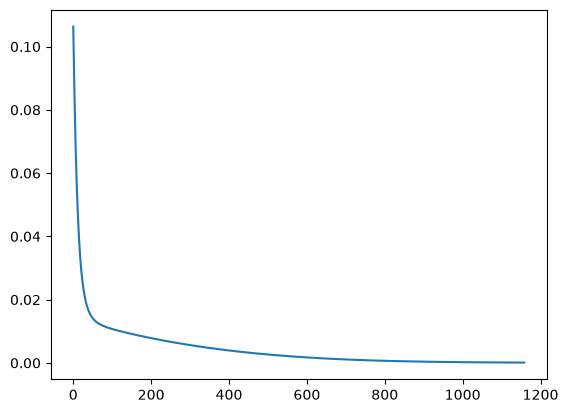

In [2417]:
ReluNN_Extra_3 = ReluNeural_Network_Extra(3)

def minimizeRelu_Extra(alpha, accuracyPoop):
    W1_init = ReluNN_Extra_3.W1
    W2_init = ReluNN_Extra_3.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_3.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_3.costFunctionPrime(X, y)

        ReluNN_Extra_3.W1 = ReluNN_Extra_3.W1 - alpha * dJdW1
        ReluNN_Extra_3.W2 = ReluNN_Extra_3.W2 - alpha * dJdW2
        ReluNN_Extra_3.W3 = ReluNN_Extra_3.W3 - alpha * dJdW3

        cost = ReluNN_Extra_3.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra = (minimizeRelu_Extra(.1, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra)


In [2418]:
three_loss = ReluNN_Extra_3.forward(X) - y

[[0.09724115 0.54679749 0.63307818]
 [0.77263824 0.14921594 0.43338719]] [[0.0168332  0.25549103 0.64182712 0.8025139  0.67459516 0.42362744
  0.77632854 0.03236051 0.31429508 0.86552718]
 [0.80127222 0.42687145 0.22939281 0.00911705 0.14611935 0.09923206
  0.55758055 0.26542314 0.20950289 0.60658785]
 [0.84135667 0.90549913 0.30242286 0.52722813 0.8763809  0.74226244
  0.04511998 0.84241434 0.5537697  0.36628924]]


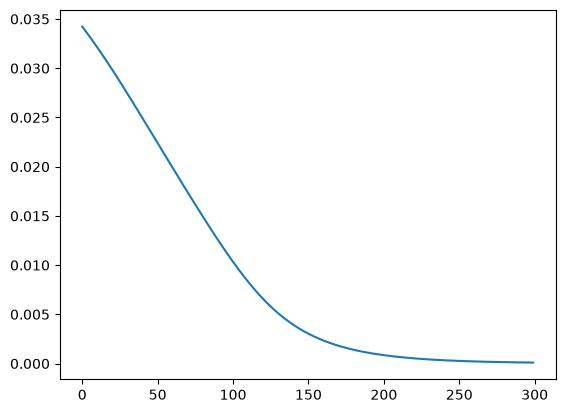

In [2419]:
ReluNN_Extra_10 = ReluNeural_Network_Extra(10)

def minimizeRelu_Extra(alpha, accuracyPoop, ReluNN_Extra_10):
    W1_init = ReluNN_Extra_10.W1
    W2_init = ReluNN_Extra_10.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_10.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_10.costFunctionPrime(X, y)

        ReluNN_Extra_10.W1 = ReluNN_Extra_10.W1 - alpha * dJdW1
        ReluNN_Extra_10.W2 = ReluNN_Extra_10.W2 - alpha * dJdW2
        ReluNN_Extra_10.W3 = ReluNN_Extra_10.W3 - alpha * dJdW3

        cost = ReluNN_Extra_10.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra_10= (minimizeRelu_Extra(.1, .0001, ReluNN_Extra_10))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra_10)



In [2420]:
ten_loss = ReluNN_Extra_10.forward(X) - y

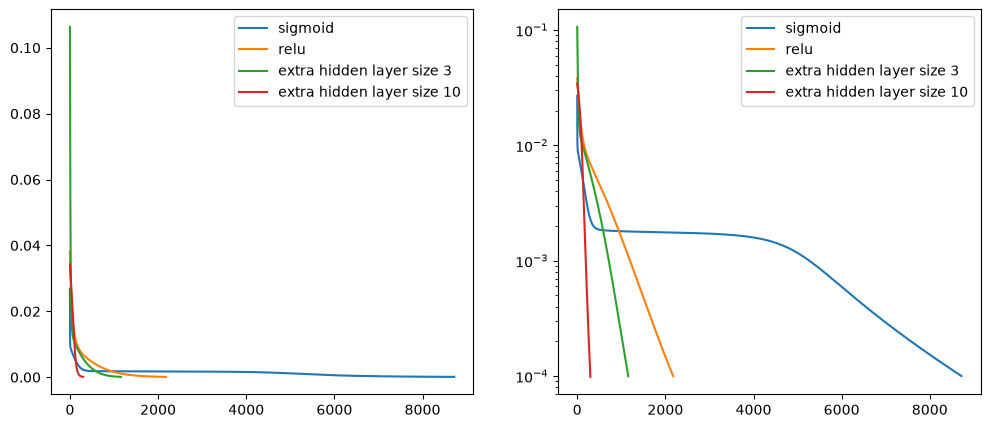

In [2421]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

for ax in (ax1, ax2):
    ax.plot(cost_arr, label = "sigmoid")
    ax.plot(cost_arrRelu, label = "relu")
    ax.plot(cost_arrRelu_Extra, label = "extra hidden layer size 3")
    ax.plot(cost_arrRelu_Extra_10, label = "extra hidden layer size 10")
    ax.legend()

ax2.set_yscale('log')

plt.show()

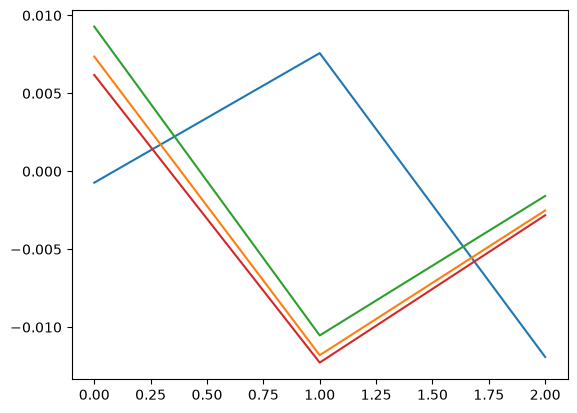

In [2422]:
plt.plot(sigmoid_loss)
plt.plot(relu_loss)
plt.plot(three_loss)
plt.plot(ten_loss)
plt.show()

In [2423]:
# Sys_1 = ReluNeural_Network()
# Sys_2 = ReluNeural_Network()
#
# Sol_1 = minimizeRelu(.1, .0001, Sys_1)
# Sol_2 = minimizeRelu(.1, .0001,Sys_2)
#
# def linear_int(Sys_1, Sys_2):
#     piv_W1 = .5*(Sys_1.W1+Sys_2.W1)
#     piv_W1_mirror = piv_W1
#     piv_W2 = .5*(Sys_1.W2+Sys_2.W2)
#     piv_W2_mirror = piv_W2
#     mirror = ReluNeural_Network
#     for i in range (500):
#         mirror.W1 = piv_W1_mirror
#         mirror.W2 = piv_W2_mirror
#         slope_W1, slope_W2 = mirror.costFunctionPrime(X,y)
#         piv_W1 = piv_W1 - 5*slope_W1
#         piv_W2 = piv_W2 - 5*slope_W2
#     costs = []
#     iterations = []
#     tester = ReluNeural_Network
#     for i in range ( 0,200, 1) :
#         if i < 100 :
#             tester.W1 = (100-i)* Sys_1.W1 + i * piv_W1
#             tester.W2 = (100-i)* Sys_1.W2 + i * piv_W2
#         else:
#             change = i-100
#             tester.W1 = (100-i)* piv_W1 + change * Sys_2.W1
#             tester.W2 = (100-i)* piv_W2 + i * Sys_2.W2
#         costs.append(tester.costFunction(X,y))
#         iterations.append(i)
#     plt.plot(iterations, costs)
#
# linear_int(Sys_1, Sys_2)


[[0.13354893 0.36348141 0.58771808]
 [0.2798458  0.97407353 0.01680858]] [[0.5695388 ]
 [0.68321728]
 [0.91861737]]
[[0.16008827 0.51298845 0.42881243]
 [0.37817488 0.29849384 0.52675934]] [[0.75476892]
 [0.83854696]
 [0.46120584]]


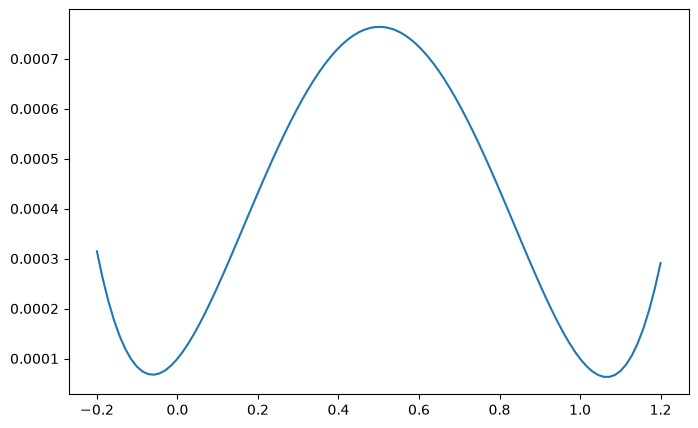

In [2424]:
Sys_1 = ReluNeural_Network()
Sys_2 = ReluNeural_Network()

Sol_1 = minimizeRelu(.1, .0001, Sys_1)
Sol_2 = minimizeRelu(.1, .0001,Sys_2)
Sys_1_W1_mirror = Sys_1.W1
Sys_1_W2_mirror = Sys_1.W2
Sys_2_W1_mirror = Sys_2.W1
Sys_2_W2_mirror = Sys_2.W2
def interpolate():
    changes = np.linspace(-.2, 1.2, 100)
    costs = []
    tester = ReluNeural_Network()
    for change in changes:
        tester.W1 = (1.0 - change) * Sys_1_W1_mirror + change * Sys_2_W1_mirror
        tester.W2 = (1.0 - change) * Sys_1_W2_mirror + change * Sys_2_W2_mirror
        costs.append(tester.costFunction(X,y))
    return changes, costs
changes, costs = interpolate()
plt.figure(figsize=(8,5))
plt.plot(changes, costs)